In [1]:
!python.exe -m pip install --upgrade pip
!pip install -q torch torchvision diffusers transformers accelerate safetensors
!pip install -q opencv-python pillow requests matplotlib rembg

In [2]:
!pip install "rembg[gpu]"

In [3]:
import torch
import numpy as np
import cv2
import requests
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from io import BytesIO

from rembg import remove, new_session

from torchvision import models
from torchvision.models import ResNet18_Weights

from diffusers import (
    StableDiffusionXLInpaintPipeline,
    StableDiffusionXLImg2ImgPipeline
)

import gc

C:\Users\admin\gpu_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import torch
print("Is CUDA available?", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU found")

Is CUDA available? True
GPU Name: NVIDIA RTX 4500 Ada Generation


In [5]:
import torch
print(torch.cuda.is_available())

True


In [6]:
if torch.cuda.is_available():
    device = "cuda"
    dtype = torch.float16
elif torch.backends.mps.is_available():
    device = "mps"
    dtype = torch.float16
else:
    device = "cpu"
    dtype = torch.float32

print("Device:", device)
print("Precision:", dtype)

if device == "cpu":
    print("Warning: SDXL can be very slow on CPU.")

Device: cuda
Precision: torch.float16


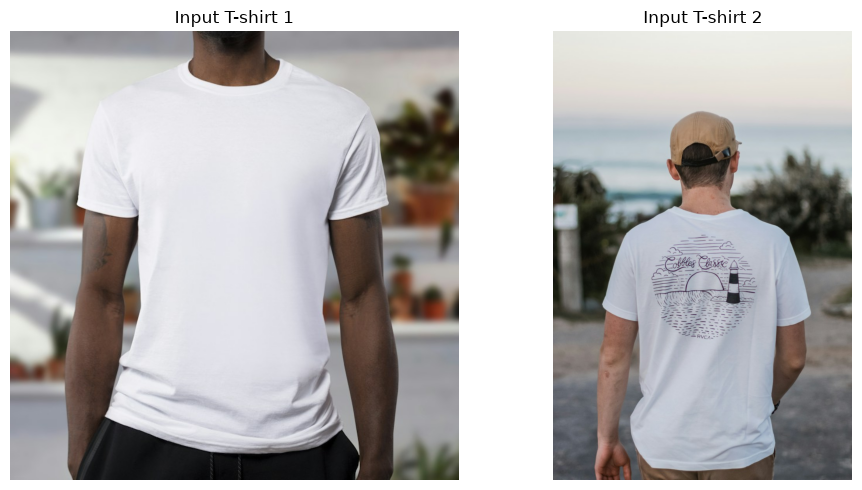

In [7]:
image_url_1 = (
    "https://images.unsplash.com/"
    "photo-1521572163474-6864f9cf17ab?w=768"
)

image_url_2 = (
    "https://images.unsplash.com/"
    "photo-1564859228273-274232fdb516?w=768"
)

response_1 = requests.get(image_url_1, timeout=30)
response_1.raise_for_status()

response_2 = requests.get(image_url_2, timeout=30)
response_2.raise_for_status()

image_1 = Image.open(
    BytesIO(response_1.content)
).convert("RGB")

image_2 = Image.open(
    BytesIO(response_2.content)
).convert("RGB")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_1)
plt.title("Input T-shirt 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_2)
plt.title("Input T-shirt 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
image_1 = ImageOps.pad(
    image_1, (768, 768),
    color="white"
)

image_2 = ImageOps.pad(
    image_2, (768, 768),
    color="white"
)

image_1_cv = cv2.cvtColor(
    np.array(image_1),
    cv2.COLOR_RGB2BGR
)

image_2_cv = cv2.cvtColor(
    np.array(image_2),
    cv2.COLOR_RGB2BGR
)

image_1_cv = cv2.fastNlMeansDenoisingColored(
    image_1_cv, None, 3, 3, 7, 21
)

image_2_cv = cv2.fastNlMeansDenoisingColored(
    image_2_cv, None, 3, 3, 7, 21
)

image_1 = Image.fromarray(
    cv2.cvtColor(image_1_cv, cv2.COLOR_BGR2RGB)
)

image_2 = Image.fromarray(
    cv2.cvtColor(image_2_cv, cv2.COLOR_BGR2RGB)
)

print("Preprocessing complete.")

Preprocessing complete.


C:\Users\admin\gpu_env\Lib\site-packages\rembg\session_factory.py:56: RuntimeWarning: CUDAExecutionProvider was requested but the session is running on CPU. onnxruntime could not load the provider, usually because the matching CUDA/cuDNN runtime libraries are missing or are a different major version than the onnxruntime-gpu build. Inference will be slow. See the onnxruntime stderr output above for the specific library that failed to load.
  return session_class(model_name, sess_opts, *args, **kwargs)


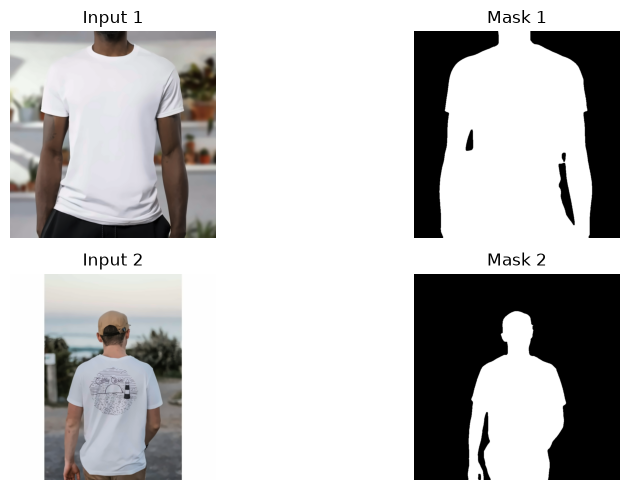

In [9]:
segmentation_session = new_session("u2net")

mask_1 = remove(
    image_1,
    session=segmentation_session,
    only_mask=True
).convert("L")

mask_2 = remove(
    image_2,
    session=segmentation_session,
    only_mask=True
).convert("L")

mask_array_1 = np.array(mask_1)
mask_array_2 = np.array(mask_2)

mask_array_1 = np.where(
    mask_array_1 > 127, 255, 0
).astype(np.uint8)

mask_array_2 = np.where(
    mask_array_2 > 127, 255, 0
).astype(np.uint8)

kernel = np.ones((5, 5), np.uint8)

mask_array_1 = cv2.erode(
    mask_array_1, kernel, iterations=1
)

mask_array_2 = cv2.erode(
    mask_array_2, kernel, iterations=1
)

mask_1 = Image.fromarray(mask_array_1)
mask_2 = Image.fromarray(mask_array_2)

plt.figure(figsize=(10, 5))

plt.subplot(2, 2, 1)
plt.imshow(image_1)
plt.title("Input 1")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(mask_1, cmap="gray")
plt.title("Mask 1")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image_2)
plt.title("Input 2")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(mask_2, cmap="gray")
plt.title("Mask 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
weights = ResNet18_Weights.DEFAULT

cnn = models.resnet18(weights=weights)
cnn.fc = torch.nn.Identity()
cnn = cnn.to(device)
cnn.eval()

cnn_transform = weights.transforms()

print("Pretrained ResNet18 loaded.")

Pretrained ResNet18 loaded.


In [11]:
tensor_1 = cnn_transform(image_1).unsqueeze(0).to(device)
tensor_2 = cnn_transform(image_2).unsqueeze(0).to(device)

with torch.no_grad():
    features_1 = cnn(tensor_1).cpu().numpy().flatten()
    features_2 = cnn(tensor_2).cpu().numpy().flatten()

print("Features for image 1:", features_1.shape)
print("Features for image 2:", features_2.shape)

Features for image 1: (512,)
Features for image 2: (512,)


In [12]:
histogram_1 = cv2.calcHist(
    [image_1_cv], [0, 1, 2],
    np.array(mask_1), [4, 4, 4],
    [0, 256, 0, 256, 0, 256]
).flatten()

histogram_2 = cv2.calcHist(
    [image_2_cv], [0, 1, 2],
    np.array(mask_2), [4, 4, 4],
    [0, 256, 0, 256, 0, 256]
).flatten()

histogram_1 = histogram_1 / (histogram_1.sum() + 1e-8)
histogram_2 = histogram_2 / (histogram_2.sum() + 1e-8)

colour_features = np.stack([
    histogram_1,
    histogram_2
])

colour_bipolar = np.where(
    colour_features > 0, 1, -1
).astype(np.float32)

cnn_features = np.stack([
    features_1,
    features_2
])

cnn_bipolar = np.where(
    cnn_features >= np.median(
        cnn_features, axis=1, keepdims=True
    ),
    1, -1
).astype(np.float32)

print("Colour features:", colour_bipolar.shape)
print("CNN features:", cnn_bipolar.shape)

Colour features: (2, 64)
CNN features: (2, 512)


In [13]:
bam_weights = np.zeros((64, 512), dtype=np.float32)

for i in range(2):
    bam_weights += np.outer(
        colour_bipolar[i],
        cnn_bipolar[i]
    )

print("BAM trained.")
print("Weight matrix:", bam_weights.shape)

BAM trained.
Weight matrix: (64, 512)


In [14]:
recalled_cnn = np.sign(
    colour_bipolar[0] @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

recalled_colour = np.sign(
    recalled_cnn @ bam_weights.T
)

recalled_colour[recalled_colour == 0] = 1

recalled_cnn = np.sign(
    recalled_colour @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

print("Colour-to-CNN recall completed.")
print("CNN-to-colour recall completed.")

Colour-to-CNN recall completed.
CNN-to-colour recall completed.


In [15]:
mixed_colour = (histogram_1 + histogram_2) / 2

mixed_colour = mixed_colour / (
    mixed_colour.sum() + 1e-8
)

mixed_bipolar = np.where(
    mixed_colour > 0, 1, -1
).astype(np.float32)

recalled_cnn = np.sign(
    mixed_bipolar @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

recalled_colour = np.sign(
    recalled_cnn @ bam_weights.T
)

recalled_colour[recalled_colour == 0] = 1

recalled_cnn = np.sign(
    recalled_colour @ bam_weights
)

recalled_cnn[recalled_cnn == 0] = 1

similarity_1 = np.mean(
    recalled_cnn == cnn_bipolar[0]
)

similarity_2 = np.mean(
    recalled_cnn == cnn_bipolar[1]
)

selected_index = int(similarity_2 > similarity_1)

print("Similarity to image 1:", similarity_1)
print("Similarity to image 2:", similarity_2)
print("Selected reference:", selected_index + 1)

source_images = [image_1, image_2, [image_1, image_2][selected_index]]
source_masks = [mask_1, mask_2, [mask_1, mask_2][selected_index]]

Similarity to image 1: 0.70703125
Similarity to image 2: 1.0
Selected reference: 2


In [16]:
prompts = [
    (
        "Photorealistic product photograph of a red cotton crew neck "
        "T-shirt with a bold black geometric graphic printed on the chest, "
        "realistic fabric texture, preserve original garment shape, "
        "clean white background, no model, no text, no watermark"
    ),
    (
        "Photorealistic product photograph of a black cotton crew neck "
        "T-shirt with a red geometric graphic printed on the chest, "
        "realistic fabric texture, preserve original garment shape, "
        "clean white background, no model, no text, no watermark"
    ),
    (
        "Photorealistic product photograph of a stylish red and black "
        "streetwear T-shirt with a modern geometric graphic, inspired by "
        "the selected reference, realistic fabric texture, clean white "
        "background, no model, no text, no watermark"
    )
]

negative_prompt = (
    "person, mannequin, hanger, distorted sleeves, extra collar, "
    "extra sleeves, deformed garment, blurry, low quality, text, "
    "letters, watermark, cropped garment"
)

print("Prompts ready.")

Prompts ready.


In [18]:
# Check whether the pipeline was loaded before the error
if "inpaint_pipe" not in globals():
    inpaint_pipe = StableDiffusionXLInpaintPipeline.from_pretrained(
        "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
        torch_dtype=dtype,
        use_safetensors=True
    )

# Apply memory optimizations supported by this version
if device == "cuda":
    inpaint_pipe.enable_model_cpu_offload()
else:
    inpaint_pipe = inpaint_pipe.to(device)

inpaint_pipe.enable_attention_slicing()

# Enable VAE tiling only if this version supports it
if hasattr(inpaint_pipe, "enable_vae_tiling"):
    inpaint_pipe.enable_vae_tiling()
    print("VAE tiling enabled.")
else:
    print("VAE tiling unavailable; continuing without it.")

print("SDXL inpainting pipeline ready.")

VAE tiling unavailable; continuing without it.
SDXL inpainting pipeline ready.


In [19]:
inpaint_outputs = []

for i in range(3):
    print("Inpainting design", i + 1, "...")

    result = inpaint_pipe(
        prompt=prompts[i],
        negative_prompt=negative_prompt,
        image=source_images[i],
        mask_image=source_masks[i],
        height=768,
        width=768,
        num_inference_steps=30,
        guidance_scale=7.5,
        strength=0.85
    )

    inpaint_outputs.append(result.images[0])

print("Inpainting generation completed.")

Inpainting design 1 ...


100%|██████████| 25/25 [00:07<00:00,  3.33it/s]


Inpainting design 2 ...


100%|██████████| 25/25 [00:07<00:00,  3.45it/s]


Inpainting design 3 ...


100%|██████████| 25/25 [00:07<00:00,  3.23it/s]


Inpainting generation completed.


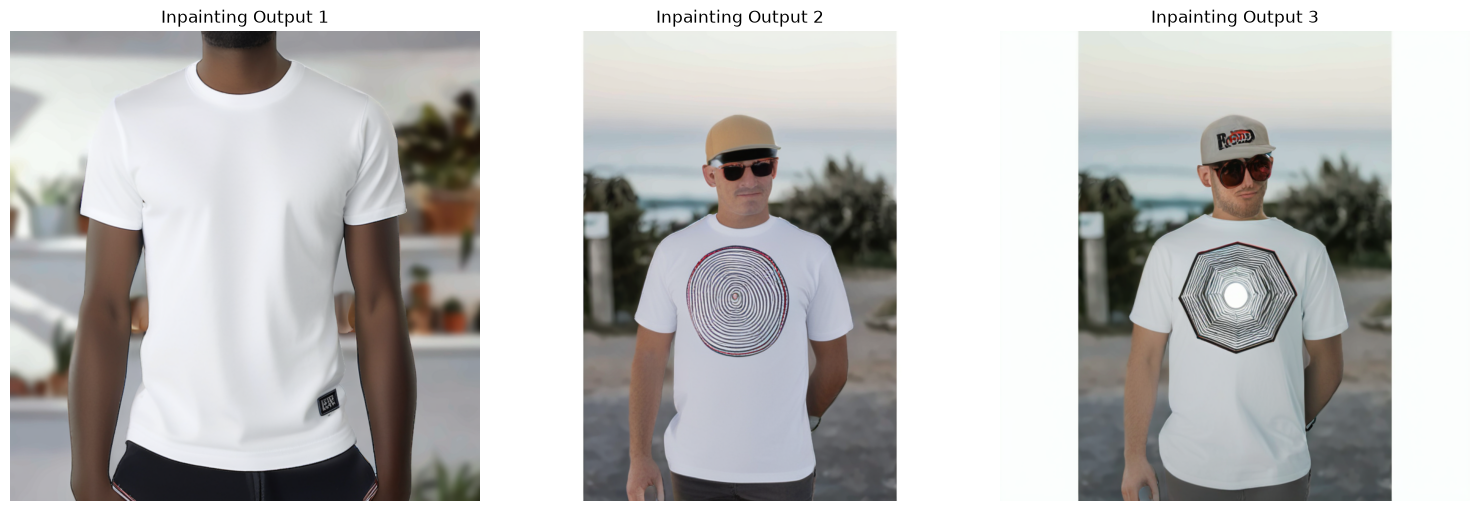

Three inpainting designs saved.


In [20]:
plt.figure(figsize=(15, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(inpaint_outputs[i])
    plt.title("Inpainting Output " + str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

for i in range(3):
    inpaint_outputs[i].save(
        "tshirt_inpainting_" + str(i + 1) + ".png"
    )

print("Three inpainting designs saved.")

In [21]:
del inpaint_pipe
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Memory cleanup completed.")

Memory cleanup completed.


In [23]:

import torch
from diffusers import StableDiffusionXLImg2ImgPipeline

model_id = "stabilityai/stable-diffusion-xl-base-1.0"

img2img_pipe = StableDiffusionXLImg2ImgPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype,
    use_safetensors=True
)

if device == "cuda":
    img2img_pipe.enable_model_cpu_offload()
else:
    img2img_pipe = img2img_pipe.to(device)

# Memory optimization
img2img_pipe.enable_attention_slicing()

# Enable VAE slicing only if supported
if hasattr(img2img_pipe, "enable_vae_slicing"):
    img2img_pipe.enable_vae_slicing()
    print("VAE slicing enabled.")
else:
    print("VAE slicing unavailable; continuing without it.")

print("SDXL image-to-image pipeline loaded successfully.")
print("Device:", device)
print("Data type:", dtype)


Loading pipeline components...: 100%|██████████| 7/7 [00:07<00:00,  1.03s/it]


VAE slicing unavailable; continuing without it.
SDXL image-to-image pipeline loaded successfully.
Device: cuda
Data type: torch.float16


In [24]:
img2img_outputs = []

for i in range(3):
    print("Generating new mockup", i + 1, "...")

    result = img2img_pipe(
        prompt=prompts[i],
        negative_prompt=negative_prompt,
        image=source_images[i],
        strength=0.80,
        num_inference_steps=30,
        guidance_scale=7.5
    )

    img2img_outputs.append(result.images[0])

print("Image-to-image generation completed.")

Generating new mockup 1 ...


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 24/24 [00:07<00:00,  3.28it/s]
C:\Users\admin\gpu_env\Lib\site-packages\diffusers\pipelines\stable_diffusion_xl\pipeline_stable_diffusion_xl_img2img.py:898: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent 

Generating new mockup 2 ...


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 24/24 [00:07<00:00,  3.38it/s]
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Generating new mockup 3 ...


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 24/24 [00:07<00:00,  3.39it/s]
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Image-to-image generation completed.


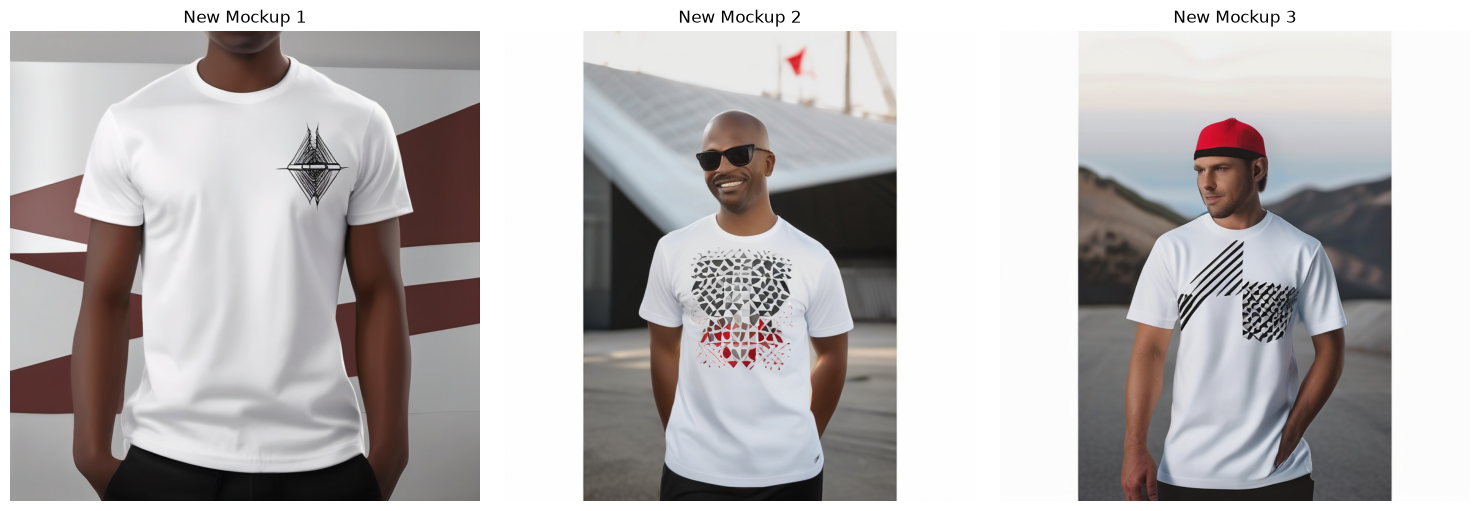

Three new mockups saved.


In [25]:
plt.figure(figsize=(15, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img2img_outputs[i])
    plt.title("New Mockup " + str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

for i in range(3):
    img2img_outputs[i].save(
        "tshirt_mockup_" + str(i + 1) + ".png"
    )

print("Three new mockups saved.")

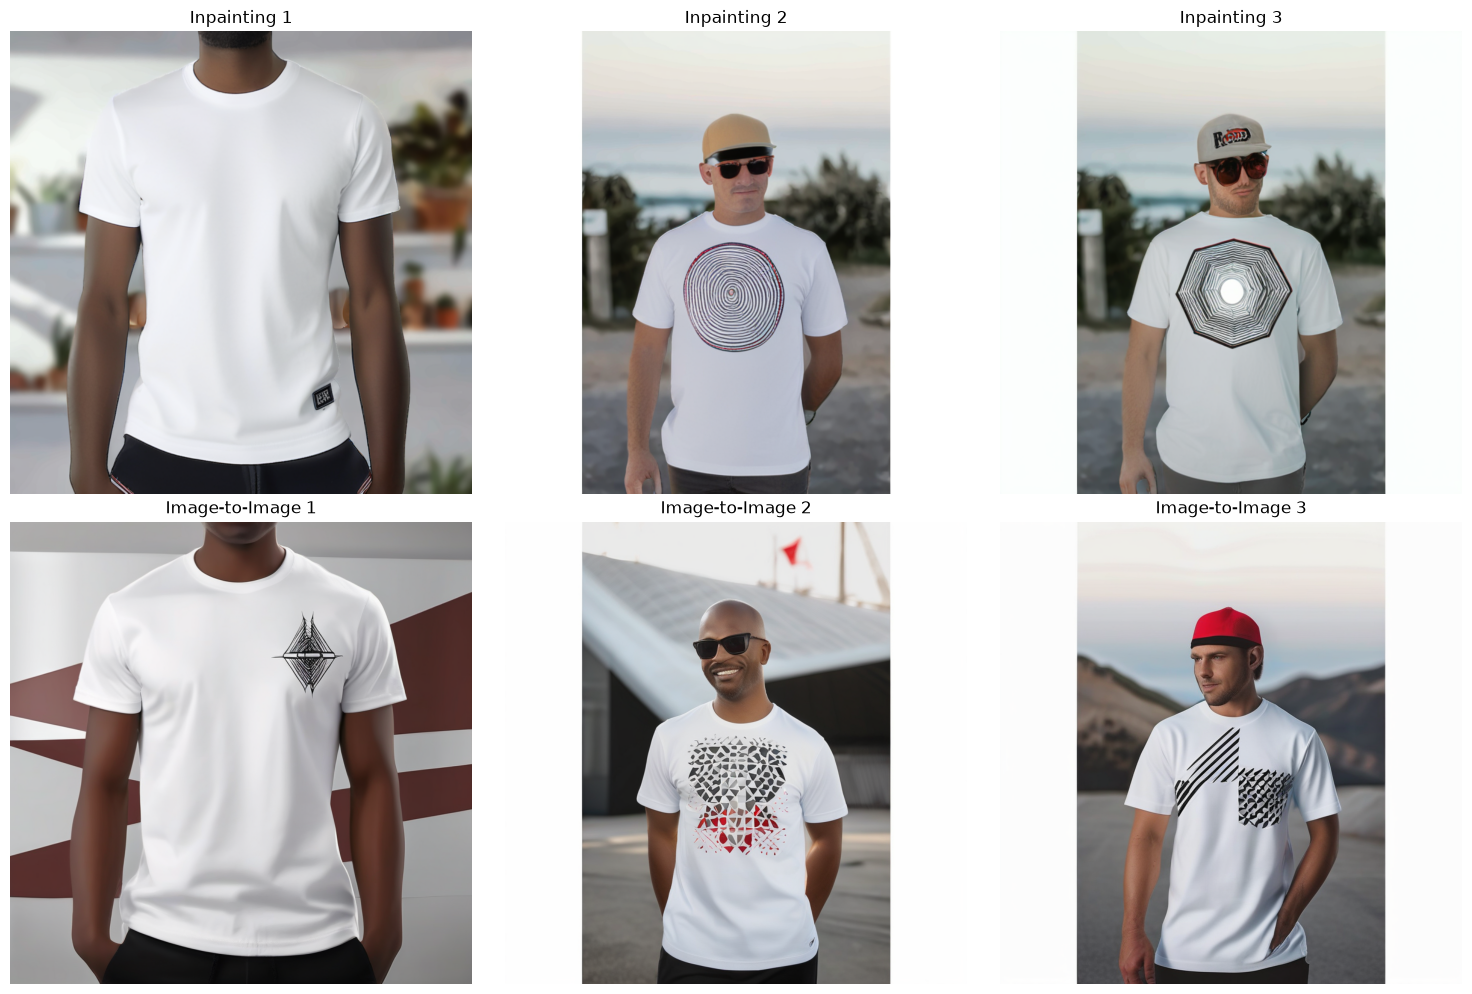

In [26]:
plt.figure(figsize=(15, 10))

for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(inpaint_outputs[i])
    plt.title("Inpainting " + str(i + 1))
    plt.axis("off")

for i in range(3):
    plt.subplot(2, 3, i + 4)
    plt.imshow(img2img_outputs[i])
    plt.title("Image-to-Image " + str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()